In [13]:
import rasterio
import numpy as np
from scipy.optimize import curve_fit
import pandas as pd
import matplotlib.pyplot as plt

## load in the data

## list of file paths for each year's raster
yearly_files = ['H:/My Drive/NDVI_Exports/step7_NDVI_2001.tif', 'H:/My Drive/NDVI_Exports/step7_NDVI_2001.tif']  # Add all your file paths here

## list to store the data for all layers
yearly_data = []

## read each raster file, including all layers in each file
for file in yearly_files:
    with rasterio.open(file) as src:
        ## read all layers (bands) in the file
        data = src.read()  # reads all bands into a 3D array (layers, rows, columns)
        yearly_data.append(data)

## stack all years along a new axis (resulting in a 4D array: [years, layers, rows, columns])
stacked_data = np.concatenate(yearly_data, axis=0)

# Check shape and data to confirm
print("Stacked Data Shape:", stacked_data.shape)  # (years * layers, rows, columns)

Stacked Data Shape: (90, 457, 881)


In [14]:
## calculate min and max along the stack (axis 0)
min_val = np.min(stacked_data, axis=0)
max_975_quantile = np.quantile(stacked_data, 0.975, axis=0)

## get the scaled data of the raster stack
scaled_data = (stacked_data - min_val) / (max_975_quantile - min_val)




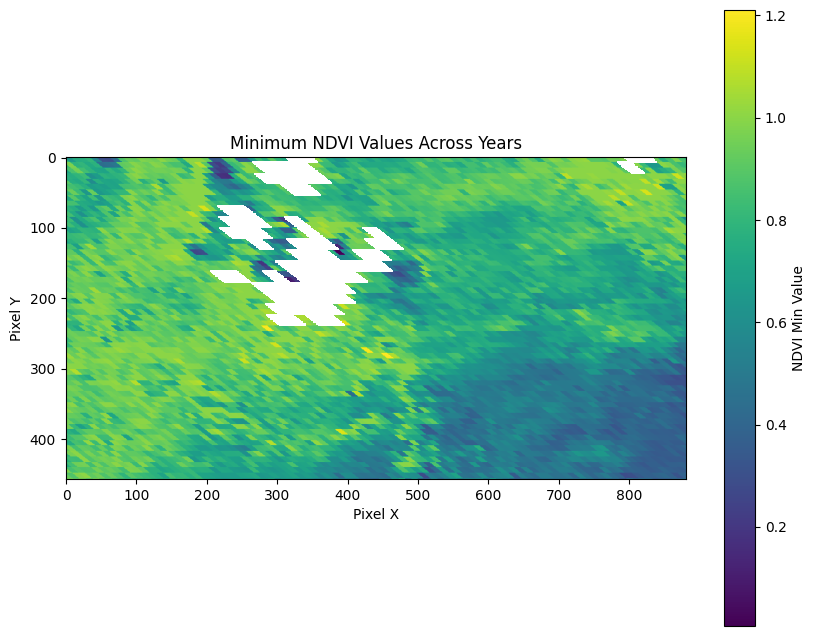

In [19]:
# Plot min_data using a color map for better visualization
plt.figure(figsize=(10, 8))
plt.imshow(scaled_data[3], cmap='viridis')
plt.colorbar(label='NDVI Min Value')
plt.title('Minimum NDVI Values Across Years')
plt.xlabel('Pixel X')
plt.ylabel('Pixel Y')
plt.show()

In [14]:
def dlc_model(time, xmidS, scalS, xmidA, scalA):
    return (1 / (1 + np.exp((xmidS - time) / scalS))) - (1 / (1 + np.exp((xmidA - time) / scalA)))


In [15]:
# Define the years corresponding to each layer in the stacked_data
start_year = 2001
end_year = 2002
# Define the years corresponding to each layer in the stacked_data
years = range(start_year, end_year + 1)

def fit_dlc(scaled_stacked_data, years):
    dlc_params = []

    for i, year in enumerate(years):
        print(f"Processing year: {year}")

        # Extract NDVI data for the year
        ndvi_values = scaled_stacked_data[i].flatten()  # Flatten to 1D

        # Generate day of the year for each pixel
        time = np.tile(np.arange(1, 366), (ndvi_values.size // 365))

        # If there were less than 4 pixels with NDVI values in the entire sequence, skip fitting
        if len(ndvi_values) < 4:
            dlc_params.append([np.nan] * 4)
            continue
        
        try:
            # Fit the curves, with bounds on the parameters
            popt, _ = curve_fit(dlc_model, time, ndvi_values, bounds=([30, 1, 167, 1], [228, 30, 288, 35]))
            dlc_params.append(popt.tolist())
        except Exception as e:
            print(f"Error fitting year {year}: {e}")
            dlc_params.append([np.nan] * 4)
    
    return dlc_params

# Fit DLC curves
dlc_params = fit_dlc(scaled_stacked_data, years)


Processing year: 2001
Error fitting year 2001: operands could not be broadcast together with shapes (402595,) (402617,) 
Processing year: 2002
Error fitting year 2002: operands could not be broadcast together with shapes (402595,) (402617,) 
